# TA-07 — Simulasi Prediksi Pertumbuhan Populasi Bakteri Menggunakan Metode Euler dan Model Logistik

**Mata Kuliah:** Pemodelan dan Simulasi (Modul 7 — Dynamic System Simulation) · **Dosen:** Mohammad Bayu Anggara, S.Kom., M.Kom.
**Nama / NIM:** *(isi nama lengkap dan NIM)*

Notebook ini memuat: (1) formulasi model Stock-Flow dan persamaan diferensial, (2) implementasi Euler, RK4, dan `scipy.integrate.solve_ivp`,
(3) kalibrasi parameter dari data, (4) visualisasi data vs simulasi, (5) eksperimen *What-If*, dan (6) validasi pada tiga skenario dataset.
Seluruh angka pada notebook dihasilkan dari eksekusi kode di bawah.

## 1. Formulasi Model Matematika

**Struktur Stock-Flow**

| Elemen | Simbol | Keterangan |
|---|---|---|
| Stock | $P(t)$ | populasi bakteri |
| Inflow | $rP$ | pertumbuhan (umpan balik **penguat**, *reinforcing*) |
| Outflow | $rP^2/K$ | pembatasan akibat kapasitas dukung (umpan balik **penyeimbang**, *balancing*) |
| Parameter | $r,\;K,\;P_0$ | laju pertumbuhan, kapasitas dukung, populasi awal |

Aliran bersih = Inflow − Outflow, sehingga diperoleh model logistik:

$$\frac{dP}{dt}=rP-\frac{rP^2}{K}=rP\left(1-\frac{P}{K}\right),\qquad P(t_0)=P_0$$

**Solusi analitik** (dipakai sebagai pembanding galat numerik):

$$P(t)=\frac{K}{1+\dfrac{K-P_0}{P_0}\,e^{-r(t-t_0)}}$$

**Metode Euler:** $P_{n+1}=P_n+h\,r\,P_n\left(1-\dfrac{P_n}{K}\right)$ dengan $h$ = ukuran langkah waktu.

## 2. Import Library dan Pengaturan

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from scipy.integrate import solve_ivp
from scipy.optimize import least_squares, curve_fit

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
DATA = Path("data") if Path("data").exists() else Path("../data")
print("Folder data:", DATA.resolve())

Folder data: /home/claude/work/proj/data


## 3. Memuat Data dan Eksplorasi Awal (EDA)

In [2]:
def muat(skenario, bagian):
    df = pd.read_csv(DATA / f"{skenario}_{bagian}.csv")
    df = df[["time", "population"]].dropna().sort_values("time").reset_index(drop=True)
    return df

SKENARIO = ["reconstruction", "extrapolation", "completion"]
for s in SKENARIO:
    for b in ["train", "test"]:
        d = muat(s, b)
        print(f"{s:14s} {b:5s} baris={len(d):3d}  t=[{d.time.min():g}, {d.time.max():g}]  P=[{d.population.min():.4f}, {d.population.max():.4f}]")

reconstruction train baris=200  t=[0, 300]  P=[2.5186, 11.9815]
reconstruction test  baris=200  t=[0, 300]  P=[2.5186, 11.9815]
extrapolation  train baris=200  t=[0, 300]  P=[2.5186, 11.9815]
extrapolation  test  baris=200  t=[0, 400]  P=[2.5186, 11.9986]
completion     train baris=200  t=[0, 300]  P=[2.5186, 11.9815]
completion     test  baris=300  t=[0, 300]  P=[2.5186, 11.9815]


Tiga skenario dataset memiliki struktur kolom yang sama (`time`, `population`). Data **train** ketiganya sama persis (diverifikasi di bawah);
perbedaannya ada pada data **test**: *reconstruction* (grid sama), *extrapolation* (waktu sampai 400), *completion* (grid lebih rapat, 300 titik).

In [3]:
tr_rec, tr_ext, tr_com = muat("reconstruction", "train"), muat("extrapolation", "train"), muat("completion", "train")
print("train reconstruction == extrapolation :", tr_rec.equals(tr_ext))
print("train reconstruction == completion    :", tr_rec.equals(tr_com))
print("test reconstruction  == train         :", muat("reconstruction", "test").equals(tr_rec))

df = tr_rec.copy()
t, P = df["time"].to_numpy(), df["population"].to_numpy()
print("\nUkuran data (baris, kolom):", df.shape)
print(df.dtypes)
print("\nMissing values :", int(df.isnull().sum().sum()))
print("Duplikat population:", int(df.population.duplicated().sum()), "| nilai unik:", df.population.nunique())
print("Selalu naik (monoton):", bool(np.all(np.diff(P) > 0)))
df.head()

train reconstruction == extrapolation : True
train reconstruction == completion    : True
test reconstruction  == train         : True

Ukuran data (baris, kolom): (200, 2)
time          float64
population    float64
dtype: object

Missing values : 0
Duplikat population: 0 | nilai unik: 200
Selalu naik (monoton): True


,time,population
0,0.000000,2.518629
1,1.507538,2.597516
2,3.015075,2.678174
3,4.522613,2.760606
4,6.030151,2.844798


In [4]:
df["population"].describe()

count    200.000000
mean       9.588753
std        2.935714
min        2.518629
25%        7.814469
50%       11.150208
75%       11.871280
max       11.981505
Name: population, dtype: float64

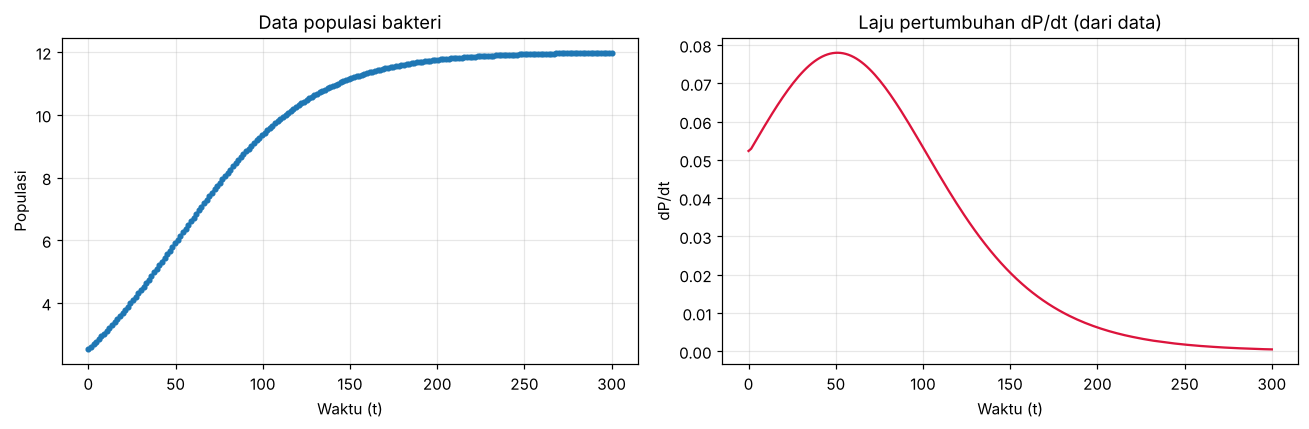

In [5]:
dPdt = np.gradient(P, t)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(t, P, "o-", ms=3); ax[0].set(title="Data populasi bakteri", xlabel="Waktu (t)", ylabel="Populasi")
ax[1].plot(t, dPdt, color="crimson"); ax[1].set(title="Laju pertumbuhan dP/dt (dari data)", xlabel="Waktu (t)", ylabel="dP/dt")
plt.tight_layout(); plt.show()

**Interpretasi.** Data berjumlah 200 observasi pada t = 0 sampai 300 (selang 1.5075), tanpa nilai hilang.
Populasi naik dari 2.5186 ke 11.9815 dengan kurva berbentuk **S (sigmoid)**; laju pertumbuhan $dP/dt$ naik, mencapai puncak, lalu turun mendekati nol —
ciri khas pertumbuhan logistik. Perhatikan: dataset ini **berbeda** dengan `bacterial_growth.csv` pada contoh tutorial modul (89 baris, populasi 0,11–0,62).

### Bukti umpan balik negatif dari data
Pada model logistik, laju per kapita $\dfrac{1}{P}\dfrac{dP}{dt}=r-\dfrac{r}{K}P$ adalah garis lurus terhadap $P$. Regresi linear pada data memberi tebakan awal $r$ dan $K$.

Regresi laju per kapita: intersep (r) = 0.026008, gradien = -0.002167, K = -intersep/gradien = 11.9995


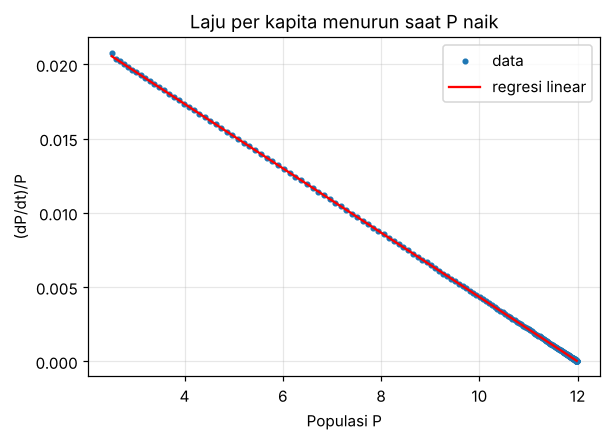

In [6]:
y = dPdt / P
gradien, intersep = np.polyfit(P, y, 1)
r_reg, K_reg = intersep, -intersep / gradien
print(f"Regresi laju per kapita: intersep (r) = {r_reg:.6f}, gradien = {gradien:.6f}, K = -intersep/gradien = {K_reg:.4f}")
plt.figure(figsize=(6, 4)); plt.plot(P, y, "o", ms=3, label="data"); plt.plot(P, gradien * P + intersep, "r-", label="regresi linear")
plt.xlabel("Populasi P"); plt.ylabel("(dP/dt)/P"); plt.title("Laju per kapita menurun saat P naik"); plt.legend(); plt.show()

## 4. Implementasi Model dan Metode Numerik

In [7]:
def logistic_model(t, P, r, K):
    """dP/dt = r P (1 - P/K)"""
    return r * P * (1 - P / K)

def solusi_analitik(t, P0, r, K, t0=0.0):
    t = np.asarray(t, float)
    return K / (1 + ((K - P0) / P0) * np.exp(-r * (t - t0)))

def euler(f, P0, t0, t_end, h, args=()):
    """P_{n+1} = P_n + h f(t_n, P_n)"""
    tg = np.arange(t0, t_end + h / 2, h)
    Pg = np.empty_like(tg); Pg[0] = P0
    for i in range(len(tg) - 1):
        Pg[i + 1] = Pg[i] + h * f(tg[i], Pg[i], *args)
    return tg, Pg

def rk4(f, P0, t0, t_end, h, args=()):
    tg = np.arange(t0, t_end + h / 2, h)
    Pg = np.empty_like(tg); Pg[0] = P0
    for i in range(len(tg) - 1):
        k1 = f(tg[i], Pg[i], *args)
        k2 = f(tg[i] + h / 2, Pg[i] + h * k1 / 2, *args)
        k3 = f(tg[i] + h / 2, Pg[i] + h * k2 / 2, *args)
        k4 = f(tg[i] + h, Pg[i] + h * k3, *args)
        Pg[i + 1] = Pg[i] + h * (k1 + 2 * k2 + 2 * k3 + k4) / 6
    return tg, Pg

def simulasi(metode, P0, r, K, t_eval, h=1.0, t0=None):
    """Hasil simulasi pada waktu t_eval (Euler/RK4: grid seragam h lalu interpolasi linear)."""
    t_eval = np.asarray(t_eval, float)
    t0 = t_eval[0] if t0 is None else t0
    if metode == "euler":
        tg, Pg = euler(logistic_model, P0, t0, t_eval[-1], h, (r, K)); return np.interp(t_eval, tg, Pg)
    if metode == "rk4":
        tg, Pg = rk4(logistic_model, P0, t0, t_eval[-1], h, (r, K)); return np.interp(t_eval, tg, Pg)
    if metode == "solve_ivp":
        s = solve_ivp(logistic_model, (t0, t_eval[-1]), [P0], args=(r, K), t_eval=t_eval, method="RK45", rtol=1e-9, atol=1e-12)
        return s.y[0]
    if metode == "analitik":
        return solusi_analitik(t_eval, P0, r, K, t0)
    raise ValueError(metode)

def metrik(y, yhat):
    e = np.asarray(yhat) - np.asarray(y)
    return {"RMSE": np.sqrt(np.mean(e**2)), "MAE": np.mean(np.abs(e)), "MAPE (%)": np.mean(np.abs(e / y)) * 100,
            "R2": 1 - np.sum(e**2) / np.sum((y - np.mean(y))**2), "Galat maks": np.max(np.abs(e))}

## 5. Kalibrasi Parameter $r$ dan $K$

$P_0$ diambil dari observasi pertama. Dua kalibrasi dilakukan hanya dengan **data train**:
(a) *curve fit* solusi analitik — menggambarkan nilai parameter 'sebenarnya' dari data; (b) *least squares* terhadap **simulasi Euler** ($h=1$) —
parameter yang dipakai pada simulator Euler (sudah menyerap sebagian galat diskretisasi).

In [8]:
P0, t0 = float(P[0]), float(t[0])
H_BASE = 1.0
batas = ([1e-6, P.max() * 0.5], [10.0, P.max() * 20])
x0 = [max(r_reg, 1e-4), max(K_reg, P.max() * 1.01)]

# (a) solusi analitik
popt, _ = curve_fit(lambda tt, r, K: solusi_analitik(tt, P0, r, K, t0), t, P, p0=x0, bounds=batas)
r_an, K_an = popt

# (b) simulasi Euler h = 1
hasil = least_squares(lambda x: simulasi("euler", P0, x[0], x[1], t, H_BASE, t0) - P, x0=x0, bounds=batas, x_scale=[0.01, 1.0])
r_eu, K_eu = hasil.x

print(f"P0 = {P0:.6f}")
print(f"(a) Analitik : r = {r_an:.8f}   K = {K_an:.6f}")
print(f"(b) Euler h=1: r = {r_eu:.8f}   K = {K_eu:.6f}")
print(f"Titik belok analitik (P = K/2) pada t = {t0 + np.log((K_an - P0) / P0) / r_an:.3f}")

P0 = 2.518629
(a) Analitik : r = 0.02600001   K = 11.999999
(b) Euler h=1: r = 0.02604376   K = 11.991925
Titik belok analitik (P = K/2) pada t = 50.985


## 6. Simulasi Euler vs Data Asli

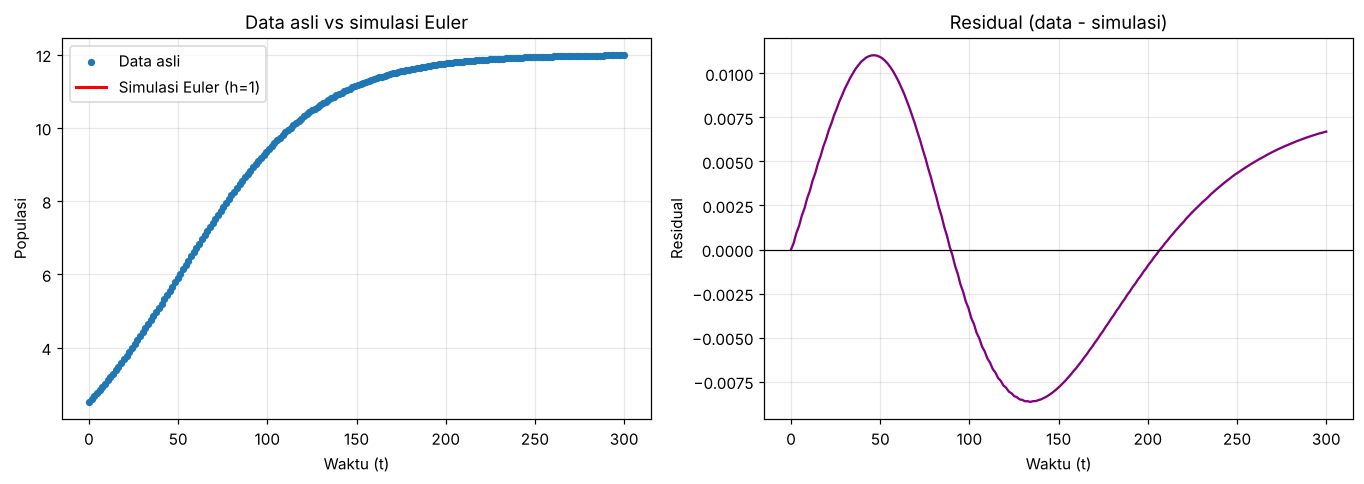

,RMSE,MAE,MAPE (%),R2,Galat maks
Euler (h=1),0.006133,0.005375,0.068702,0.999996,0.011035


In [9]:
tg, Pg = euler(logistic_model, P0, t0, t.max(), H_BASE, (r_eu, K_eu))
pred = simulasi("euler", P0, r_eu, K_eu, t, H_BASE, t0)
fig, ax = plt.subplots(1, 2, figsize=(12.5, 4.5))
ax[0].scatter(t, P, s=14, c="tab:blue", label="Data asli", zorder=3)
ax[0].plot(tg, Pg, "r-", lw=2, label=f"Simulasi Euler (h={H_BASE:g})")
ax[0].set(title="Data asli vs simulasi Euler", xlabel="Waktu (t)", ylabel="Populasi"); ax[0].legend()
ax[1].plot(t, P - pred, color="purple"); ax[1].axhline(0, color="k", lw=0.8)
ax[1].set(title="Residual (data - simulasi)", xlabel="Waktu (t)", ylabel="Residual")
plt.tight_layout(); plt.show()
pd.Series(metrik(P, pred), name="Euler (h=1)").to_frame().T

**Interpretasi.** Kurva simulasi berimpit dengan data. RMSE Euler = 0.00613, MAE = 0.00537, R² = 0.999996,
galat maksimum 0.01103 pada populasi yang bernilai 2,5–12. Garis data dan simulasi **tidak berhimpit sempurna** karena
(i) Euler hanya aproksimasi orde-1 sehingga ada galat diskretisasi, (ii) $r$ dan $K$ hasil kalibrasi adalah estimasi, dan (iii) model logistik adalah penyederhanaan realitas.

## 7. Perbandingan Metode: Euler, RK4, `solve_ivp`, dan Solusi Analitik

In [10]:
daftar = [("Euler (h=1)", "euler", 1.0, (r_eu, K_eu)), ("RK4 (h=1)", "rk4", 1.0, (r_an, K_an)),
          ("solve_ivp (RK45)", "solve_ivp", 1.0, (r_an, K_an)), ("Analitik", "analitik", 1.0, (r_an, K_an))]
baris = []
for nama, m, h, (r_, K_) in daftar:
    baris.append({"Metode": nama, "r": r_, "K": K_, **metrik(P, simulasi(m, P0, r_, K_, t, h, t0))})
pd.DataFrame(baris).round(8)

,Metode,r,K,RMSE,MAE,MAPE (%),R2,Galat maks
0,Euler (h=1),0.026044,11.991925,0.006133,0.005375,0.068702,0.999996,0.011035
1,RK4 (h=1),0.026000,11.999999,0.000040,0.000029,0.000421,1.000000,0.000098
2,solve_ivp (RK45),0.026000,11.999999,0.000005,0.000003,0.000030,1.000000,0.000027
3,Analitik,0.026000,11.999999,0.000005,0.000003,0.000030,1.000000,0.000027


RK4 (4.02e-05) dan `solve_ivp` (5.01e-06) jauh lebih akurat daripada Euler pada langkah yang sama (6.13e-03),
sesuai teori orde akurasi (Euler orde 1, RK4 orde 4, RK45 adaptif). Galat `solve_ivp`/analitik sebesar ~5×10⁻⁶ adalah galat kalibrasi terhadap data (presisi data).

## 8. Pengaruh Ukuran Langkah $h$ pada Metode Euler

,h,r*h,RMSE vs analitik,RMSE vs data,P maks
0,100.0,2.600001,2.134422,2.134421,14.825382
1,75.0,1.950001,0.631891,0.631891,12.218795
2,50.0,1.300000,0.425962,0.425962,12.029652
3,30.0,0.780000,0.252386,0.252385,11.999687
4,15.0,0.390000,0.124087,0.124087,11.994530
5,10.0,0.260000,0.082045,0.082045,11.991065
6,5.0,0.130000,0.040626,0.040626,11.986718
7,2.0,0.052000,0.016145,0.016144,11.983698
8,1.0,0.026000,0.008054,0.008053,11.982624
9,0.5,0.013000,0.004022,0.004022,11.982075


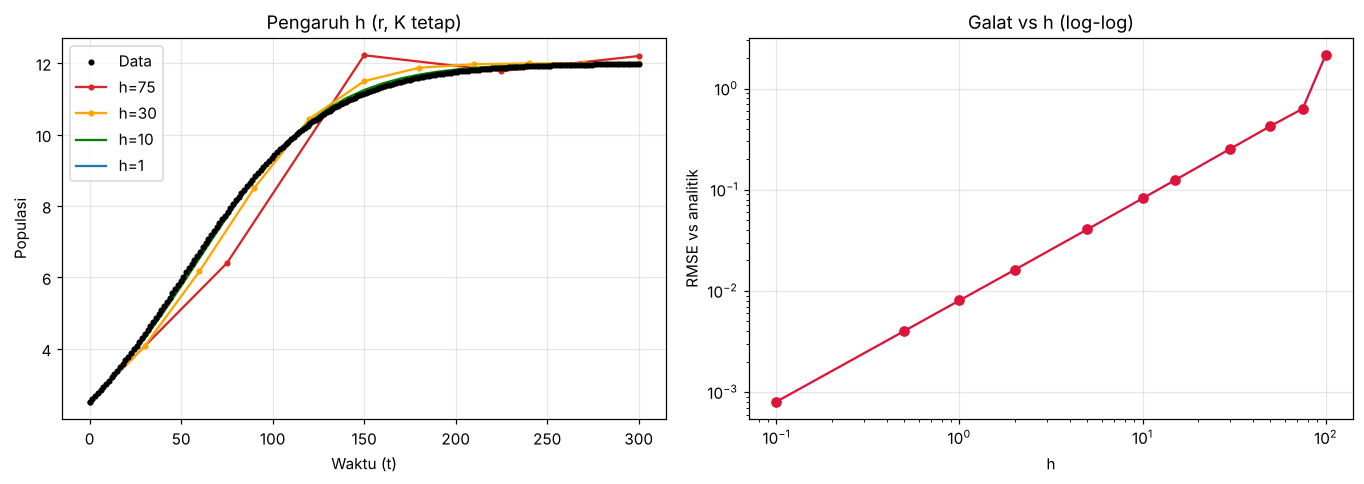

Kemiringan log-log (h <= 10): 1.004 -> orde galat ~ O(h)


In [11]:
pa = simulasi("analitik", P0, r_an, K_an, t, t0=t0)
hs = [100, 75, 50, 30, 15, 10, 5, 2, 1, 0.5, 0.1]
baris = []
for h in hs:
    pe = simulasi("euler", P0, r_an, K_an, t, h, t0)
    baris.append({"h": h, "r*h": r_an * h, "RMSE vs analitik": metrik(pa, pe)["RMSE"], "RMSE vs data": metrik(P, pe)["RMSE"], "P maks": pe.max()})
tab_h = pd.DataFrame(baris)
display(tab_h)

fig, ax = plt.subplots(1, 2, figsize=(12.5, 4.5))
ax[0].scatter(t, P, s=9, c="k", label="Data", zorder=5)
for h, c in [(75, "tab:red"), (30, "orange"), (10, "green"), (1, "tab:blue")]:
    tg_, Pg_ = euler(logistic_model, P0, t0, t.max(), h, (r_an, K_an)); ax[0].plot(tg_, Pg_, "-o" if h >= 30 else "-", ms=3, color=c, label=f"h={h}")
ax[0].set(title="Pengaruh h (r, K tetap)", xlabel="Waktu (t)", ylabel="Populasi"); ax[0].legend()
ax[1].loglog(tab_h["h"], tab_h["RMSE vs analitik"], "o-", color="crimson"); ax[1].set(title="Galat vs h (log-log)", xlabel="h", ylabel="RMSE vs analitik")
plt.tight_layout(); plt.show()
m = tab_h["h"] <= 10
print("Kemiringan log-log (h <= 10):", round(np.polyfit(np.log(tab_h.h[m]), np.log(tab_h["RMSE vs analitik"][m]), 1)[0], 3), "-> orde galat ~ O(h)")

**Interpretasi.** Galat Euler turun kira-kira sebanding dengan $h$ (kemiringan log-log ≈ 1.00, konsisten dengan orde-1): RMSE terhadap solusi analitik
2.134 pada $h=100$, 0.082 pada $h=10$, 0.0081 pada $h=1$, dan 0.00080 pada $h=0.1$.
Pada $h=100$ ($r\cdot h$ = 2.60 > 2) simulasi melampaui kapasitas K (P maks = 14.83 > 12.0): titik kesetimbangan $K$ tidak lagi stabil pada skema Euler
karena faktor galat $|1-rh|$ melebihi 1. Jadi $h$ kecil = akurat tetapi lebih banyak langkah; $h$ besar = cepat tetapi tidak akurat/tidak stabil.

## 9. Eksperimen What-If

Baseline = parameter terkalibrasi Euler. Skenario: laju $r$ ±50%, kapasitas $K$ ±25%, dan $P_0$ turun 50%. Semua disimulasikan dengan Euler ($h=1$) sampai $t=300$.

,Skenario,r,K,P0,P akhir (t=300),"Waktu P=0,5K","Waktu P=0,9K",Laju maks,Selisih P akhir vs baseline
0,Baseline,0.0260,11.9919,2.5186,11.9748,51.0727,134.9296,0.0781,0.0000
1,r turun 50%,0.0130,11.9919,2.5186,11.1534,101.9390,270.1624,0.0390,-0.8214
2,r naik 50%,0.0391,11.9919,2.5186,11.9916,34.1175,89.8538,0.1171,0.0168
3,K turun 25%,0.0260,8.9939,2.5186,8.9852,36.3659,120.2240,0.0586,-2.9896
4,K naik 25%,0.0260,14.9899,2.5186,14.9616,61.7155,145.5744,0.0976,2.9868
5,P0 turun 50%,0.0260,11.9919,1.2593,11.9525,82.7634,166.6222,0.0781,-0.0223


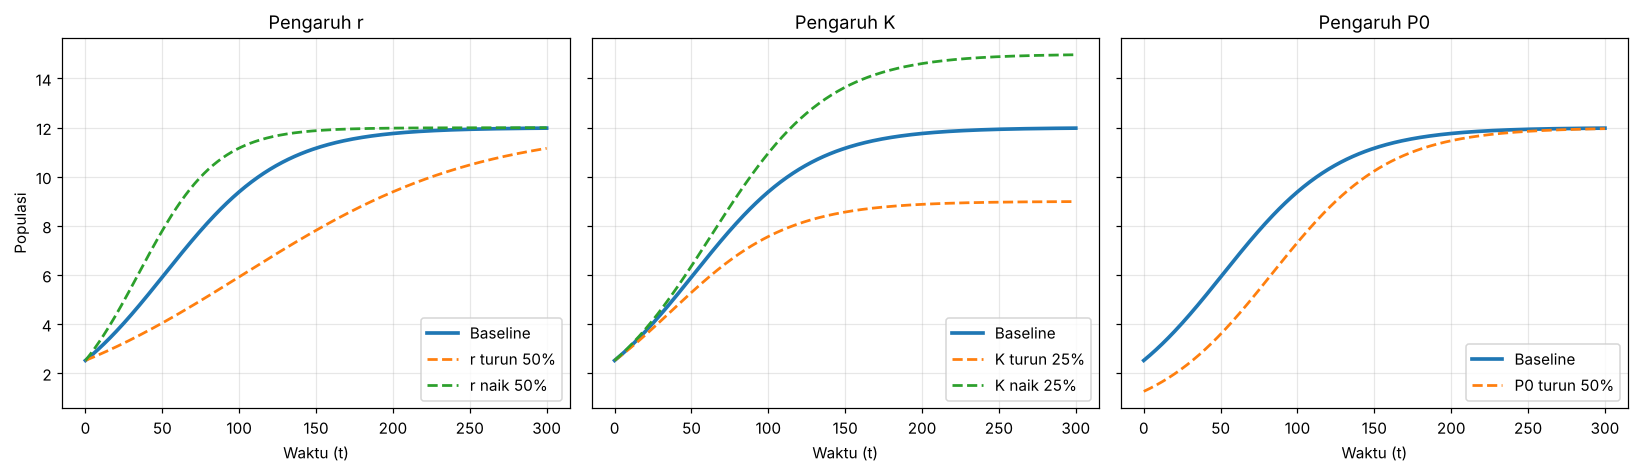

In [12]:
base = dict(P0=P0, r=r_eu, K=K_eu)
skenario = {"Baseline": base,
            "r turun 50%": {**base, "r": 0.5 * r_eu}, "r naik 50%": {**base, "r": 1.5 * r_eu},
            "K turun 25%": {**base, "K": 0.75 * K_eu}, "K naik 25%": {**base, "K": 1.25 * K_eu},
            "P0 turun 50%": {**base, "P0": 0.5 * P0}}
def waktu_mencapai(tg, Pg, target):
    idx = np.where(Pg >= target)[0]
    if len(idx) == 0: return np.nan
    i = idx[0]
    return tg[0] if i == 0 else tg[i-1] + (target - Pg[i-1]) * (tg[i] - tg[i-1]) / (Pg[i] - Pg[i-1])

kurva, baris = {}, []
for nama, p in skenario.items():
    tg_, Pg_ = euler(logistic_model, p["P0"], t0, 300.0, H_BASE, (p["r"], p["K"]))
    kurva[nama] = (tg_, Pg_)
    baris.append({"Skenario": nama, "r": p["r"], "K": p["K"], "P0": p["P0"], "P akhir (t=300)": Pg_[-1],
                  "Waktu P=0,5K": waktu_mencapai(tg_, Pg_, 0.5 * p["K"]), "Waktu P=0,9K": waktu_mencapai(tg_, Pg_, 0.9 * p["K"]),
                  "Laju maks": np.gradient(Pg_, tg_).max(), "Selisih P akhir vs baseline": Pg_[-1] - kurva["Baseline"][1][-1]})
tab_wi = pd.DataFrame(baris); display(tab_wi.round(4))

fig, ax = plt.subplots(1, 3, figsize=(15, 4.4), sharey=True)
grup = [("Pengaruh r", ["Baseline", "r turun 50%", "r naik 50%"]), ("Pengaruh K", ["Baseline", "K turun 25%", "K naik 25%"]), ("Pengaruh P0", ["Baseline", "P0 turun 50%"])]
for a, (jd, ks) in zip(ax, grup):
    for kk in ks:
        a.plot(*kurva[kk], lw=2.4 if kk == "Baseline" else 1.8, ls="-" if kk == "Baseline" else "--", label=kk)
    a.set(title=jd, xlabel="Waktu (t)"); a.legend(loc="lower right")
ax[0].set_ylabel("Populasi"); plt.tight_layout(); plt.show()

**Interpretasi (dari tabel di atas).**
- **r turun 50%** → pertumbuhan jauh lebih lambat: waktu mencapai 0,9K menjadi 270.2 (baseline 134.9), dan pada t = 300 populasi baru 11.15
  (selisih -0.82). **r naik 50%** mempercepat ke 89.9. Nilai akhir tetap ≈ K: **r mengubah kecepatan, bukan batas akhir.**
- **K turun 25%** → populasi jenuh di sekitar 8.99 (selisih -2.99); **K naik 25%** → 14.96. **K menentukan level jenuh**, dan laju maksimum $rK/4$ ikut berubah.
- **P0 turun 50%** → fase pertumbuhan baru dimulai lebih lambat (0,5K tercapai pada t ≈ 82.8 vs 51.1), tetapi nilai akhir sama (11.95): **P0 menggeser waktu, bukan tujuan akhir.**

### Skenario kejadian mendadak: 50% populasi mati pada $t=100$

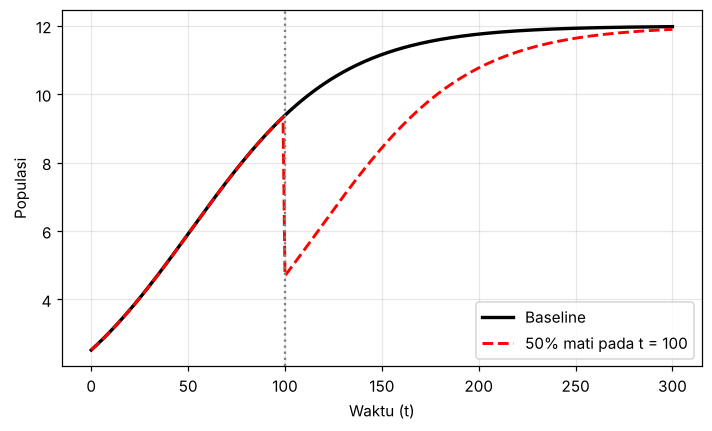

P akhir: 11.8951 | selisih vs baseline: -0.0797
Waktu P=0,9K  skenario: 200.87 | baseline: 134.93


In [13]:
def euler_kejadian(P0_, r_, K_, h, t_kej, faktor, T=300.0):
    tg_ = np.arange(t0, T + h / 2, h); Pg_ = np.empty_like(tg_); Pg_[0] = P0_; sudah = False
    for i in range(len(tg_) - 1):
        if (not sudah) and tg_[i] >= t_kej:
            Pg_[i] *= faktor; sudah = True
        Pg_[i + 1] = Pg_[i] + h * logistic_model(tg_[i], Pg_[i], r_, K_)
    return tg_, Pg_
tg1, Pg1 = euler_kejadian(P0, r_eu, K_eu, H_BASE, 100.0, 0.5)
tgb, Pgb = kurva["Baseline"]
plt.figure(figsize=(7.5, 4.2)); plt.plot(tgb, Pgb, "k", lw=2.2, label="Baseline"); plt.plot(tg1, Pg1, "r--", lw=1.9, label="50% mati pada t = 100")
plt.axvline(100, color="gray", ls=":"); plt.xlabel("Waktu (t)"); plt.ylabel("Populasi"); plt.legend(); plt.show()
print("P akhir:", round(Pg1[-1], 4), "| selisih vs baseline:", round(Pg1[-1] - Pgb[-1], 4))
print("Waktu P=0,9K  skenario:", round(waktu_mencapai(tg1, Pg1, 0.9 * K_eu), 2), "| baseline:", round(waktu_mencapai(tgb, Pgb, 0.9 * K_eu), 2))

Setelah populasi dipangkas separuh, sistem **pulih sendiri** karena umpan balik: populasi yang lebih kecil memiliki faktor $(1-P/K)$ lebih besar sehingga tumbuh lebih cepat.
Waktu mencapai 0,9K mundur dari 134.9 menjadi 200.9, dan pada t = 300 selisih terhadap baseline tinggal -0.080.

## 10. Validasi pada Tiga Skenario Dataset

Untuk tiap skenario, $r$ dan $K$ dikalibrasi (Euler, $h=1$) **hanya** dari data *train*, lalu diuji pada data *test*.

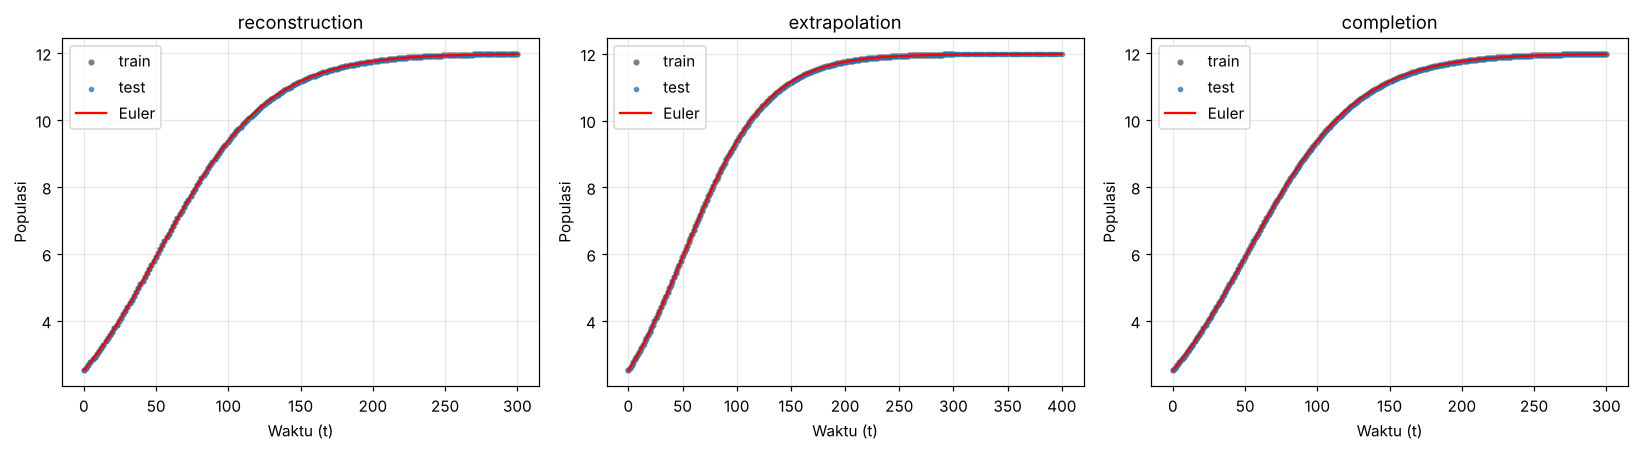

,Skenario,Bagian,n,t maks,r,K,RMSE,MAE,MAPE (%),R2,Galat maks
0,reconstruction,train,200,300.0,0.026044,11.991925,0.006133,0.005375,0.068702,0.999996,0.011035
1,reconstruction,test,200,300.0,0.026044,11.991925,0.006133,0.005375,0.068702,0.999996,0.011035
2,extrapolation,train,200,300.0,0.026044,11.991925,0.006133,0.005375,0.068702,0.999996,0.011035
3,extrapolation,test,200,400.0,0.026044,11.991925,0.006509,0.005909,0.067236,0.999994,0.011038
4,extrapolation,test (t>300),50,400.0,0.026044,11.991925,0.007532,0.007524,0.062736,NaN,0.007926
5,completion,train,200,300.0,0.026044,11.991925,0.006133,0.005375,0.068702,0.999996,0.011035
6,completion,test,300,300.0,0.026044,11.991925,0.006132,0.005377,0.068846,0.999996,0.011041


In [14]:
def kalibrasi_euler(d):
    tt, PP = d.time.to_numpy(), d.population.to_numpy()
    g, c = np.polyfit(PP, np.gradient(PP, tt) / PP, 1)
    x0_ = [max(c, 1e-4), max(-c / g, PP.max() * 1.01)]
    bt = ([1e-6, PP.max() * 0.5], [10.0, PP.max() * 20])
    s = least_squares(lambda x: simulasi("euler", PP[0], x[0], x[1], tt, 1.0, tt[0]) - PP, x0=x0_, bounds=bt, x_scale=[0.01, 1.0])
    return s.x

baris = []
fig, ax = plt.subplots(1, 3, figsize=(15, 4.2))
for a, s in zip(ax, SKENARIO):
    trn, tst = muat(s, "train"), muat(s, "test")
    r_, K_ = kalibrasi_euler(trn)
    for bag, d in [("train", trn), ("test", tst)]:
        pr = simulasi("euler", trn.population.iloc[0], r_, K_, d.time.to_numpy(), 1.0, trn.time.iloc[0])
        baris.append({"Skenario": s, "Bagian": bag, "n": len(d), "t maks": d.time.max(), "r": r_, "K": K_, **metrik(d.population.to_numpy(), pr)})
    if s == "extrapolation":
        luar = tst[tst.time > trn.time.max()]
        pr = simulasi("euler", trn.population.iloc[0], r_, K_, tst.time.to_numpy(), 1.0, trn.time.iloc[0])[tst.time.to_numpy() > trn.time.max()]
        mm = metrik(luar.population.to_numpy(), pr); mm["R2"] = np.nan   # R2 tidak bermakna: variansi populasi pada t>300 sangat kecil
        baris.append({"Skenario": s, "Bagian": "test (t>300)", "n": len(luar), "t maks": luar.time.max(), "r": r_, "K": K_, **mm})
    a.scatter(trn.time, trn.population, s=9, c="gray", label="train"); a.scatter(tst.time, tst.population, s=7, c="tab:blue", alpha=.7, label="test")
    tg_, Pg_ = euler(logistic_model, trn.population.iloc[0], trn.time.iloc[0], max(tst.time.max(), trn.time.max()), 1.0, (r_, K_))
    a.plot(tg_, Pg_, "r-", label="Euler"); a.set(title=s, xlabel="Waktu (t)", ylabel="Populasi"); a.legend()
plt.tight_layout(); plt.show()
pd.DataFrame(baris).round(6)

**Interpretasi.** Pada *extrapolation* (t sampai 400) model yang dikalibrasi hanya dari t ≤ 300 tetap akurat pada seluruh data uji (RMSE 0.00651)
dan pada bagian di luar rentang latih saja t > 300 (RMSE 0.00753, MAPE 0.063%).
R² pada subset t > 300 tidak dilaporkan karena populasi hampir konstan di rentang itu (variansi sangat kecil membuat R² tidak bermakna).
Pada *completion* (grid lebih rapat, RMSE 0.00613) dan *reconstruction* (data uji identik dengan data latih) hasilnya setara.
Perlu dicatat bahwa baik *train* maupun *test* berasal dari kurva yang sangat halus; hasil ini tidak otomatis berlaku untuk data laboratorium yang berisik.

## 11. Kesimpulan

1. Dataset populasi bakteri (200 titik, t = 0–300) berpola sigmoid dan sangat sesuai dengan **model logistik**: parameter terkalibrasi $r\approx0.0260$ dan $K\approx12.000$ (solusi analitik), atau $r=0.02604$, $K=11.9919$ pada simulasi Euler $h=1$.
2. **Euler ($h=1$)** meniru data dengan RMSE 0.00613 (R² = 0.999996); RK4 dan `solve_ivp` lebih akurat dengan biaya komputasi yang lebih besar per langkah.
3. Galat Euler ∝ $h$ (orde-1) dan menjadi tidak stabil bila $r\cdot h>2$.
4. Analisis **What-If**: $r$ menentukan *kecepatan*, $K$ menentukan *level jenuh*, $P_0$ menentukan *waktu mulai*; sistem yang terganggu pulih karena *balancing loop*.
5. **Keterbatasan:** model deterministik satu variabel tanpa fase lag/kematian/noise; data bersifat sangat halus; kalibrasi memakai *least squares* tanpa interval kepercayaan.